#Loading and Preprocessing
1. Load the Iris dataset from sklearn.  
2. Drop the species column since this is a clustering problem.

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [10]:
iris = load_iris(as_frame=True)
df = iris.frame

print("Before:", df.columns.tolist())
df = df.drop(columns=['target'])
print("After:", df.columns.tolist())

df.head()

Before: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']
After: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# scaling the features

In [11]:
scaler = StandardScaler()
X = scaler.fit_transform(df)


#1. KMeans Clustering :  
● Provide a brief description of how KMeans clustering works.  
● Explain why KMeans clustering might be suitable for the Iris dataset.  
● Apply KMeans clustering to the preprocessed Iris dataset and visualize the clusters.

This is how Kmeans work, KMeans sorts data into k groups. First, it picks k starting points called centroids. Then it repeats two steps: (1) give each data point to its nearest centroid, and (2) move each centroid to the middle of its group. It stops when the centroids no longer move

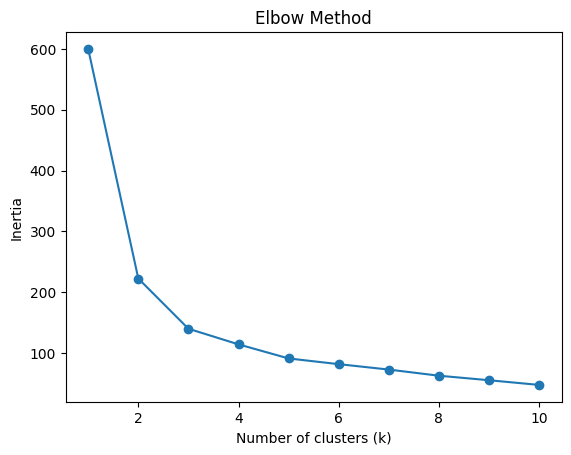

In [16]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

K mean clustering suits Iris data because the Iris data is small and all numbers, and the flowers form tight, round groups, which is what KMeans works best on. The dataset has 3 flower species, so we use k = 3. The species names are not used for clustering. We only use them to choose k, and the elbow method also supports this choice.

In [17]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

print(df['cluster'].value_counts())

cluster
0    53
1    50
2    47
Name: count, dtype: int64


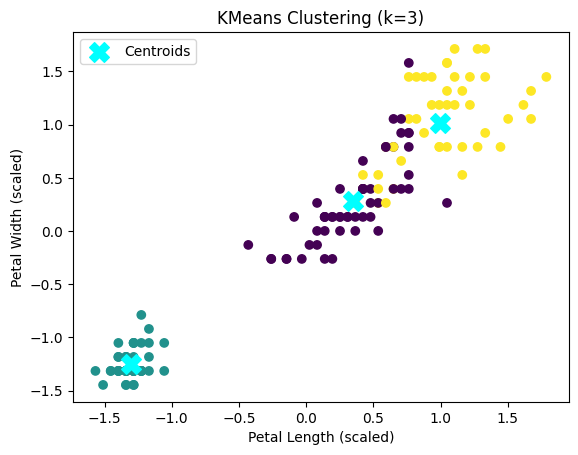

In [27]:
import matplotlib.pyplot as plt

centroids = kmeans.cluster_centers_


plt.scatter(X[:, 2], X[:, 3], c=df['cluster'])
plt.scatter(centroids[:, 2], centroids[:, 3], c='cyan', marker='X', s=200, label='Centroids')

plt.xlabel('Petal Length (scaled)')
plt.ylabel('Petal Width (scaled)')
plt.title('KMeans Clustering (k=3)')
plt.legend()
plt.show()

KMeans formed three clusters (53, 50, 47). The cluster of 50 is setosa, and the other two differ slightly because versicolor and virginica overlap.

#2. Hierarchical Clustering
● Provide a brief description of how Hierarchical clustering works.  
● Explain why Hierarchical clustering might be suitable for the Iris dataset.  
● Apply Hierarchical clustering to the preprocessed Iris dataset and visualize the clusters



* Hierarchical clustering starts by treating every flower as its own group. Then it keeps joining the two closest groups until only one big group is left. This builds a tree called a dendrogram. Cutting the tree at the right height gives the final clusters.
* The Iris data is small, so the tree is quick to build. It doesn’t need random starting points, and the dendrogram picture helps us choose how many clusters to use.  



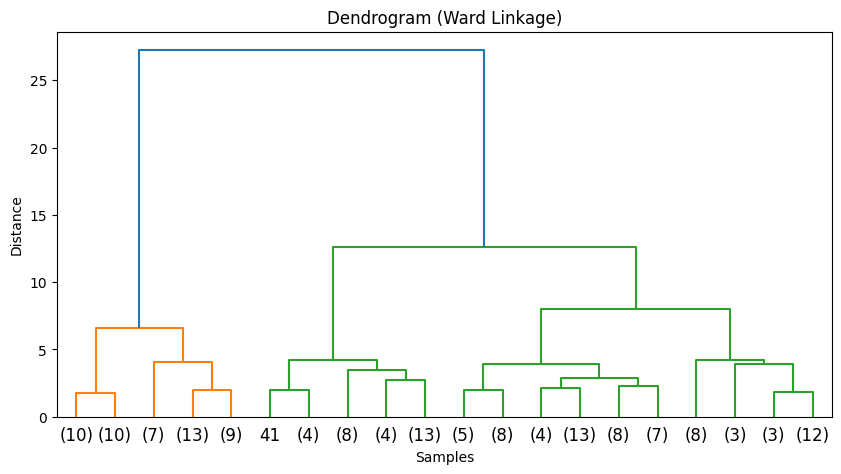

In [31]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

Z = linkage(X, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=20)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.show()

The dendrogram first splits into two main branches at a large distance. The right branch then splits again, giving three clusters in total. This matches the three species, so we choose k = 3.

In [29]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['hc_cluster'] = hc.fit_predict(X)

print(df['hc_cluster'].value_counts())

hc_cluster
0    71
1    49
2    30
Name: count, dtype: int64


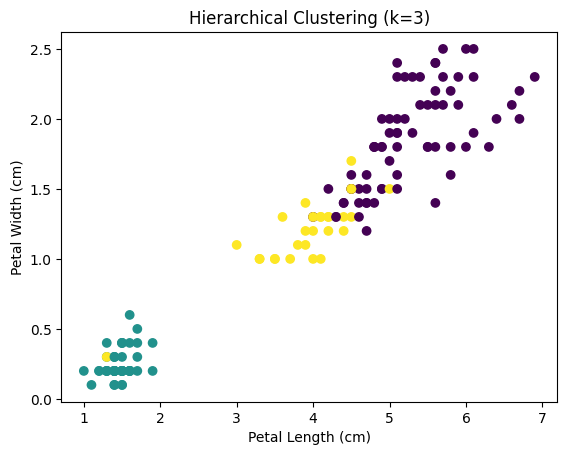

In [30]:
plt.scatter(df['petal length (cm)'], df['petal width (cm)'], c=df['hc_cluster'])
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Hierarchical Clustering (k=3)')
plt.show()